In [ ]:
# q1 - beta bernoulli
# Levi Félix Barbosa - 579420

import numpy as np
import matplotlib.pyplot as plt
from math import lgamma

N, N1 = 10, 8

In [ ]:
def beta_pdf(t, a, b):
    logB = lgamma(a) + lgamma(b) - lgamma(a + b)
    return np.exp((a - 1) * np.log(t) + (b - 1) * np.log(1 - t) - logB)


# posteriori é Beta(a+N1, b+N-N1), dai saem os tres estimadores
def estimativas(a, b):
    ml = N1 / N
    mapa = (a + N1 - 1) / (a + b + N - 2)
    media = (a + N1) / (a + b + N)
    return ml, mapa, media

In [3]:
for a, b in [(1, 1), (2, 2)]:
    ml, mapa, media = estimativas(a, b)
    print(f"priori Beta({a},{b})  ->  posteriori Beta({a + N1},{b + N - N1})")
    print(f"  ML     = {ml:.4f}")
    print(f"  MAP    = {mapa:.4f}")
    print(f"  E[t|D] = {media:.4f}")
    print()

# com a=b=1 a priori é uniforme e o MAP da igual ao ML
# com a=b=2 a priori puxa tudo pra perto de 0.5

priori Beta(1,1)  ->  posteriori Beta(9,3)
  ML     = 0.8000
  MAP    = 0.8000
  E[t|D] = 0.7500

priori Beta(2,2)  ->  posteriori Beta(10,4)
  ML     = 0.8000
  MAP    = 0.7500
  E[t|D] = 0.7143



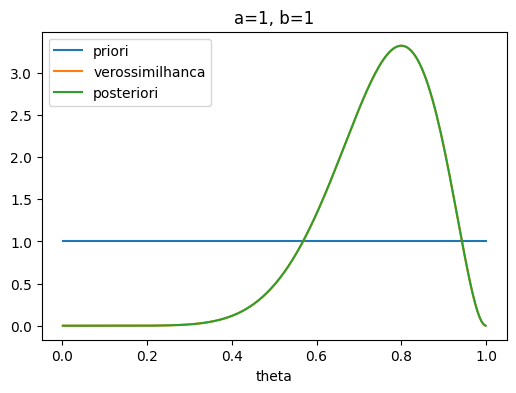

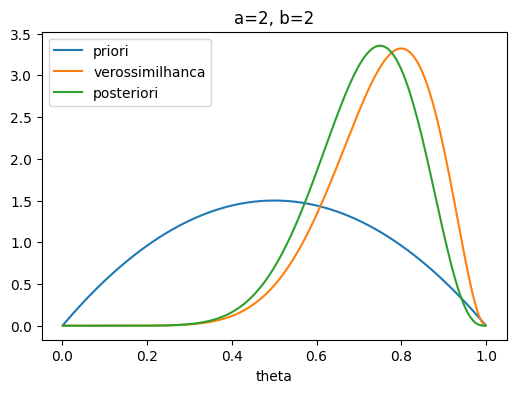

In [ ]:
t = np.linspace(0.001, 0.999, 200)

# normalizei so pra caber na mesma escala
vero = t ** N1 * (1 - t) ** (N - N1)
vero = vero / np.trapezoid(vero, t)

for a, b in [(1, 1), (2, 2)]:
    plt.figure(figsize=(6, 4))
    plt.plot(t, beta_pdf(t, a, b), label="priori")
    plt.plot(t, vero, label="verossimilhanca")
    plt.plot(t, beta_pdf(t, a + N1, b + N - N1), label="posteriori")
    plt.title(f"a={a}, b={b}")
    plt.xlabel("theta")
    plt.legend()
    plt.show()

# no primeiro grafico posteriori e verossimilhanca dao a mesma curva e ficam
# uma em cima da outra, é esperado (priori uniforme nao muda nada)